# Part 2: Perceptron with Regularization

Training three Perceptron models on `sms_spam_perceptron.csv`:

| Model | Setting |
|---|---|
| Original | `Perceptron(penalty=None, ...)` |
| L1 | `Perceptron(penalty='l1', ...)` |
| L2 | `Perceptron(penalty='l2', ...)` |

Recall the Perceptron score: $z = \mathbf{w}^T\mathbf{x} + b$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
np.set_printoptions(precision=4, suppress=True)

## 1. Load the dataset

In [2]:
df = pd.read_csv("datasets/sms_spam_perceptron.csv")
print("Shape:", df.shape)
df.head()

Shape: (99, 3)


,type,sex,buy
0,ham,0,1
1,ham,0,1
2,ham,1,1
3,spam,1,0
4,ham,0,1


## 2. Features and labels
The `type` column is the label (spam = 1, ham = 0); all other columns (`sex`, `buy`) are the features.

In [3]:
y = df.iloc[:, 0].values
y = np.where(y == 'spam', -1, 1)     # spam = -1, ham = 1 (as in class)

X = df.iloc[:, [1, 2]].values
feature_cols = list(df.columns[[1, 2]])

print("Features:", feature_cols)
print("Labels: spam = -1, ham = 1")
print(pd.Series(y).value_counts())

Features: ['sex', 'buy']
Labels: spam = -1, ham = 1
 1    75
-1    24
Name: count, dtype: int64


## 3. Train/test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (69, 2)  Test size: (30, 2)


## 4. Train the three Perceptron models
Only `penalty` changes; every other parameter is fixed.

In [5]:
COMMON_PARAMS = dict(
    max_iter=40,
    eta0=0.1,
    random_state=0,
    tol=None,
    alpha=0.0001,
)

model_specs = {
    "Original (None)": None,
    "L1": "l1",
    "L2": "l2",
}

models, rows = {}, []
for name, penalty in model_specs.items():
    clf = Perceptron(penalty=penalty, **COMMON_PARAMS)
    clf.fit(X_train, y_train)
    models[name] = clf

    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    w = clf.coef_.ravel()

    rows.append({
        "Model": name,
        "penalty": str(penalty),
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Bias (intercept_)": round(float(clf.intercept_[0]), 4),
        "||w||_1": round(np.abs(w).sum(), 4),
        "||w||_2": round(np.linalg.norm(w), 4),
        "max |w|": round(np.abs(w).max(), 4),
        "# zero weights": int(np.sum(np.isclose(w, 0))),
        "Epochs (n_iter_)": clf.n_iter_,
    })

results = pd.DataFrame(rows).set_index("Model")
results

,penalty,Train Accuracy,Test Accuracy,Bias (intercept_),||w||_1,||w||_2,max |w|,# zero weights,Epochs (n_iter_)
Model,,,,,,,,,
Original (None),None,0.8551,0.9,0.3,0.5000,0.4123,0.4000,0,40
L1,l1,0.8551,0.9,0.4,0.6448,0.5770,0.5724,0,40
L2,l2,0.8551,0.9,0.5,0.7850,0.6930,0.6859,0,40


## 5. Learned weights (`coef_`) and bias (`intercept_`)

In [6]:
for name, clf in models.items():
    print(f"===== {name} =====")
    print("coef_ (weights):\n", clf.coef_)
    print("intercept_ (bias):", clf.intercept_)
    print()

===== Original (None) =====
coef_ (weights):
 [[-0.4 -0.1]]
intercept_ (bias): [0.3]

===== L1 =====
coef_ (weights):
 [[-0.5724 -0.0724]]
intercept_ (bias): [0.4]

===== L2 =====
coef_ (weights):
 [[-0.6859 -0.0991]]
intercept_ (bias): [0.5]



### Weights side-by-side (one row per feature)

In [7]:
weights_table = pd.DataFrame(
    {name: clf.coef_.ravel() for name, clf in models.items()},
    index=feature_cols,
)
weights_table.loc["bias (intercept_)"] = [clf.intercept_[0] for clf in models.values()]
weights_table.round(4)

,Original (None),L1,L2
sex,-0.4,-0.5724,-0.6859
buy,-0.1,-0.0724,-0.0991
bias (intercept_),0.3,0.4000,0.5000


## 6. Visual comparison

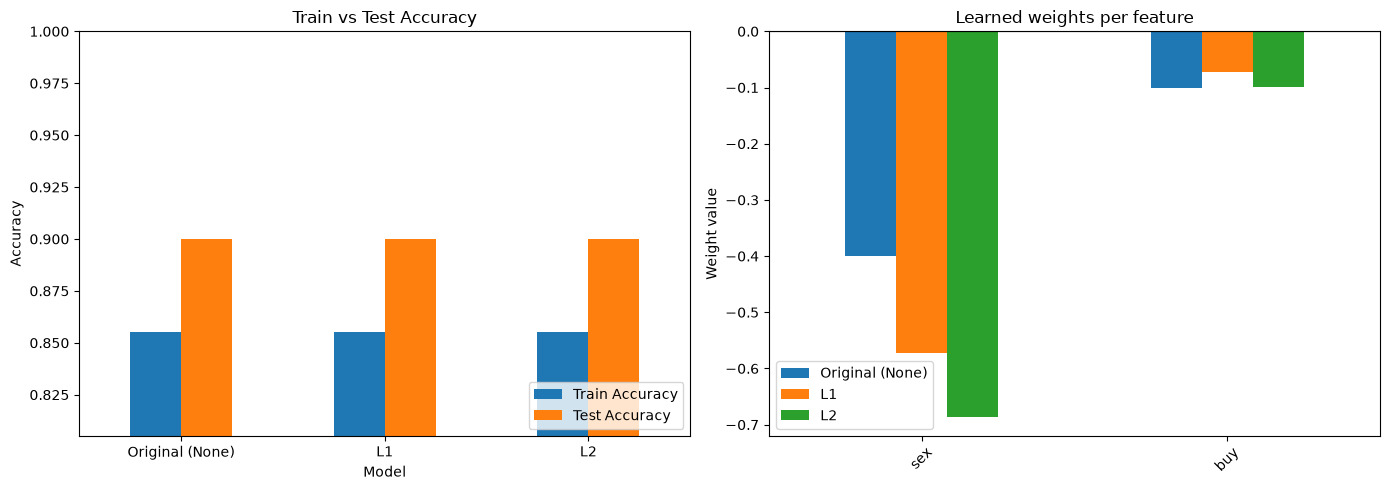

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
results[["Train Accuracy", "Test Accuracy"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Train vs Test Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(max(0, results[["Train Accuracy", "Test Accuracy"]].values.min() - 0.05), 1.0)
axes[0].legend(loc="lower right")

# Weight comparison
weights_table.drop(index="bias (intercept_)").plot(kind="bar", ax=axes[1])
axes[1].set_title("Learned weights per feature")
axes[1].set_ylabel("Weight value")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("part2_regularization.png", dpi=150)
plt.show()

## 7. Automatic summary of the differences

In [9]:
base = results.loc["Original (None)"]
for name in ["L1", "L2"]:
    r = results.loc[name]
    print(f"{name} vs Original:")
    print(f"  Test accuracy change : {r['Test Accuracy'] - base['Test Accuracy']:+.4f}")
    print(f"  Train accuracy change: {r['Train Accuracy'] - base['Train Accuracy']:+.4f}")
    print(f"  ||w||_2 ratio        : {r['||w||_2'] / base['||w||_2']:.3f}")
    print(f"  Zero weights         : {r['# zero weights']} (original: {base['# zero weights']})")
    print()

L1 vs Original:
  Test accuracy change : +0.0000
  Train accuracy change: +0.0000
  ||w||_2 ratio        : 1.399
  Zero weights         : 0 (original: 0)

L2 vs Original:
  Test accuracy change : +0.0000
  Train accuracy change: +0.0000
  ||w||_2 ratio        : 1.681
  Zero weights         : 0 (original: 0)



## 8. Analysis

The three models performed exactly the same. Each one had 85.51% training accuracy and 90% testing accuracy, which is also what we got in class with the original Perceptron. They also made the same predictions on every message, so adding L1 or L2 regularization did not change how well the model classified spam and ham.
 
The difference was in the learned weights. Since spam is labeled -1 and ham is labeled 1, a negative weight means the word pushes a message toward spam. In all three models both words had negative weights, but "sex" always had a much bigger weight than "buy", which means "sex" is the more important word for detecting spam.
 
The original Perceptron had weights of -0.4 for "sex" and -0.1 for "buy", with a bias of 0.3. With L1, "sex" changed to -0.5724, "buy" changed to -0.0724, and the bias was 0.4. With L2, "sex" changed to -0.6859, "buy" changed to -0.0991, and the bias was 0.5.
 
I expected regularization to make the weights smaller, but the "sex" weight actually got bigger with both L1 and L2. The only weight that moved toward zero was "buy" with L1, which is what L1 is known for, since it tries to push less important weights to zero. L2 is supposed to shrink all weights a little without making any of them zero, but that effect didn't really show up here. I think this happened because the regularization strength (alpha) was left at the default value of 0.0001, which is very small. The penalty was too weak to shrink the weights directly. Instead it just changed the training process slightly, so each model ended up with different final weights.
 
Accuracy stayed the same because the Perceptron only cares whether the score is positive or negative, not how big it is. Even though the weights were different, all three models ended up with the same rule: if "sex" shows up at least once, the message is classified as spam, and otherwise it is classified as ham. Because of this, all of their predictions matched.
 
Overall, L1 and L2 regularization changed the weights but did not improve or hurt the classification performance on this dataset. This makes sense because the dataset is small, the model only uses two features, and it was not overfitting, so there was not much for regularization to fix. A larger alpha or a dataset with more features would probably show a bigger difference between the three models.